# Screen Box videos for bioluminescent signals

Analyze multiple deployments independently. Videos are downloaded one at a time, measured with `scripts/brightnessOverTime.py`, then deleted. View-level CSVs are retained under `data/processed/brightness_parts/<dataset>/`. Aug 23 black and Aug 24 green use only their functioning right views; Aug 24 black treats the two views as technical replicates and averages matched frames for plotting. The Aug 24 green folder contains 335 shorter videos (2.152 GB total).

In [5]:
DATASETS = [
    {
        "key": "aug23_manglar_black",
        "label": "Aug 23 – Punta Manglar (black smalle)",
        "box_url": "https://ucsb.box.com/s/g5dt84y2krfraipbbjjaligjh8u49qag",
        "notes": ("Black smalle placed at punta Manglar near the far pylons, specifically "
                  "the one closest to the mangroves. The view direction is away from the mangroves."),
        "conditions": ("Partly cloudy and calm. The Moon was visible and bright. "
                       "Visibility was good."),
        "regions": ["right"],  # the other camera recorded white
        "results_subdir": None,  # reuse the existing Aug 23 CSV location
        "batch_start": 0, "batch_size": 31,
    },
    {
        "key": "aug24_manglar_black",
        "label": "Aug 24 – Punta Manglar (black smalle)",
        "box_url": "https://ucsb.box.com/s/vonqpn2z455bvy2dcv6q0gqo63w5pxfq",
        "notes": ("Black smalle placed at punta manglar near the far pylons. "
                  "Placed in the same location as the previous night."),
        "conditions": ("Rainy night, but still fairly calm. It was quite dark because "
                       "of the cloud cover. Visibility was not good."),
        "interpretation_notes": ("BoT activity early in the night may mainly be "
                                 "lightning, based on a quick check."),
        "calibration_notes": ("Around 19:00, I placed my fluorescent calibration tile "
                              "in front of each camera, including placing it on the ground."),
        "regions": ["left", "right"],  # technical replicates
        "results_subdir": "aug24_manglar_black",
        "batch_start": 0, "batch_size": 31,
    },
    {
        "key": "aug24_manglar_green",
        "label": "Aug 24 – Punta Manglar (green smalle)",
        "box_url": "https://ucsb.box.com/s/zj2zoeejxa4a76xmqzw8wo8shw9pgeym",
        "notes": ("Punta manglar close to smalle-black, but approximately 5 m closer "
                  "to mangroves - still facing the same cardinal direction (away from "
                  "mangroves) on Thalassia."),
        "conditions": ("Rainy night, but still fairly calm. It was quite dark because "
                       "of the cloud cover. Visibility was not good."),
        "interpretation_notes": ("BoT activity early in the night may mainly be "
                                 "lightning, based on a quick check."),
        "calibration_notes": ("Around 19:00, I placed my fluorescent calibration tile "
                              "in front of each camera, including placing it on the ground."),
        "regions": ["right"],  # the left camera recorded white
        "results_subdir": "aug24_manglar_green",
        "expected_video_count": 335,
        "batch_start": 0, "batch_size": 335,  # the complete Box folder
    },
]
FRAME_STEP = 3
MAX_WIDTH = 640  # applied after selecting a camera half
TIMEZONE = "America/Panama"
TOP_FRACTION, PERCENTILE, BRIGHT_THRESHOLD = 0.001, 99.9, 200
FORCE_REPROCESS = False
MEAN_Y_AXIS_MAX, BRIGHT_Y_AXIS_MAX = 0.05, 50

In [6]:
import importlib.util, json, re, sys, tempfile, time, urllib.error, urllib.parse, urllib.request
from pathlib import Path
from zoneinfo import ZoneInfo
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "scripts" / "brightnessOverTime.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
SCRIPT_PATH = PROJECT_ROOT / "scripts" / "brightnessOverTime.py"
RESULTS_ROOT = PROJECT_ROOT / "data" / "processed" / "brightness_parts"
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
spec = importlib.util.spec_from_file_location("brightness_over_time", SCRIPT_PATH)
brightness = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = brightness
spec.loader.exec_module(brightness)
print(f"Using {SCRIPT_PATH}")

Using /Users/oakley/Documents/GitHub/manta-analysis/scripts/brightnessOverTime.py


In [7]:
BOX_DATA_RE = re.compile(r"Box\.(?:postStreamData|prefetchedData)\s*=\s*(\{.*?\});", re.DOTALL)
VIDEO_EXTENSIONS = {"avi", "m4v", "mkv", "mov", "mp4", "mpg", "mpeg"}

def _read_url(url, attempts=4):
    headers = {"User-Agent": "Mozilla/5.0", "Accept": "text/html,application/xhtml+xml"}
    for attempt in range(1, attempts + 1):
        try:
            with urllib.request.urlopen(urllib.request.Request(url, headers=headers), timeout=60) as response:
                return response.read().decode("utf-8")
        except (urllib.error.HTTPError, urllib.error.URLError, TimeoutError) as error:
            if attempt == attempts:
                raise RuntimeError(f"Box request failed after {attempts} attempts: {url}") from error
            time.sleep(2 ** (attempt - 1))

def list_box_videos(shared_url):
    rows, page = [], 1
    while True:
        html = _read_url(f"{shared_url}{'&' if '?' in shared_url else '?'}page={page}")
        candidates = [json.loads(match.group(1)) for match in BOX_DATA_RE.finditer(html)]
        post_data = next(
            (data for data in candidates if "/app-api/enduserapp/shared-folder" in data), None
        )
        if post_data is None:
            raise RuntimeError("Could not find Box folder metadata. Check that the link is public.")
        folder = post_data["/app-api/enduserapp/shared-folder"]
        rows.extend({"id": int(item["id"]), "name": item["name"],
                     "size_bytes": int(item["itemSize"])}
                    for item in folder["items"]
                    if item.get("type") == "file"
                    and item.get("extension", "").lower() in VIDEO_EXTENSIONS)
        if page >= int(folder["pageCount"]):
            break
        page += 1
    if not rows:
        raise RuntimeError(f"No videos found in {shared_url}")
    table = pd.DataFrame(rows).drop_duplicates("id")
    table["size_GB"] = table["size_bytes"] / 1e9
    table["start_utc"] = table["name"].map(brightness.parse_utc_start)
    shared_name = post_data["/app-api/enduserapp/shared-item"]["sharedName"]
    return table.sort_values(["start_utc", "name"]).reset_index(drop=True), shared_name

def download_box_file(shared_name, file_id, destination, block_size=8 * 1024 * 1024):
    query = urllib.parse.urlencode({"rm": "box_download_shared_file",
                                    "shared_name": shared_name, "file_id": f"f_{file_id}"})
    request = urllib.request.Request(f"https://ucsb.app.box.com/index.php?{query}",
                                     headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request, timeout=120) as response, destination.open("wb") as output:
        total, downloaded = int(response.headers.get("Content-Length", 0)), 0
        while block := response.read(block_size):
            output.write(block); downloaded += len(block)
            if total:
                print(f"\rDownloaded {downloaded / total:6.1%}", end="")
    print()

## List and select each dataset

This fetches only Box listing pages. Adjust each dataset's batch fields above before processing.

In [8]:
dataset_runs = {}
for config in DATASETS:
    videos, shared_name = list_box_videos(config["box_url"])
    start, stop = config["batch_start"], config["batch_start"] + config["batch_size"]
    selected = videos.iloc[start:stop].copy()
    results_dir = (RESULTS_ROOT / config["results_subdir"]
                   if config["results_subdir"] else RESULTS_ROOT)
    results_dir.mkdir(parents=True, exist_ok=True)
    selected["completed_views"] = selected["name"].map(lambda name: sum(
        (results_dir / f"{Path(name).stem}_{region}_brightness.csv").exists()
        for region in config["regions"]))
    selected["required_views"] = len(config["regions"])
    dataset_runs[config["key"]] = dict(config=config, videos=videos, selected=selected,
                                                shared_name=shared_name, results_dir=results_dir)
    print(f"\n{config['label']}\nNotes: {config['notes']}")
    print(f"Conditions: {config['conditions']}")
    if interpretation := config.get("interpretation_notes"):
        print(f"Interpretation note: {interpretation}")
    if calibration := config.get("calibration_notes"):
        print(f"Calibration note: {calibration}")
    print(f"Found {len(videos)} videos ({videos['size_GB'].sum():.2f} GB total)")
    if expected := config.get("expected_video_count"):
        status = "matches" if len(videos) == expected else "DOES NOT MATCH"
        print(f"Expected count: {expected} videos — {status} Box listing")
    display(selected[["name", "size_GB", "start_utc", "completed_views", "required_views"]]
            .style.format({"size_GB": "{:.3f}"}))


Aug 23 – Punta Manglar (black smalle)
Notes: Black smalle placed at punta Manglar near the far pylons, specifically the one closest to the mangroves. The view direction is away from the mangroves.
Found 31 videos (5.27 GB total)


,name,size_GB,start_utc,completed_views,required_views
0,sbs_20260824_000601.mkv,0.579,2026-08-24 00:06:01+00:00,1,1
1,sbs_20260824_002601.mkv,0.039,2026-08-24 00:26:01+00:00,1,1
2,sbs_20260824_004601.mkv,0.040,2026-08-24 00:46:01+00:00,1,1
3,sbs_20260824_010601.mkv,0.040,2026-08-24 01:06:01+00:00,1,1
4,sbs_20260824_012601.mkv,0.039,2026-08-24 01:26:01+00:00,1,1
5,sbs_20260824_014601.mkv,0.038,2026-08-24 01:46:01+00:00,1,1
6,sbs_20260824_020601.mkv,0.040,2026-08-24 02:06:01+00:00,1,1
7,sbs_20260824_022602.mkv,0.040,2026-08-24 02:26:02+00:00,1,1
8,sbs_20260824_024601.mkv,0.042,2026-08-24 02:46:01+00:00,1,1
9,sbs_20260824_030602.mkv,0.039,2026-08-24 03:06:02+00:00,1,1



Aug 24 – Punta Manglar (black smalle)
Notes: Black smalle placed at punta manglar near the far pylons. Placed in the same location as the previous night.
Found 31 videos (2.75 GB total)


,name,size_GB,start_utc,completed_views,required_views
0,sbs_20260825_003709.mkv,0.099,2026-08-25 00:37:09+00:00,2,2
1,sbs_20260825_005709.mkv,0.103,2026-08-25 00:57:09+00:00,2,2
2,sbs_20260825_011709.mkv,0.109,2026-08-25 01:17:09+00:00,2,2
3,sbs_20260825_013709.mkv,0.102,2026-08-25 01:37:09+00:00,2,2
4,sbs_20260825_015709.mkv,0.103,2026-08-25 01:57:09+00:00,2,2
5,sbs_20260825_021710.mkv,0.164,2026-08-25 02:17:10+00:00,2,2
6,sbs_20260825_023710.mkv,0.205,2026-08-25 02:37:10+00:00,2,2
7,sbs_20260825_025710.mkv,0.162,2026-08-25 02:57:10+00:00,2,2
8,sbs_20260825_031710.mkv,0.098,2026-08-25 03:17:10+00:00,2,2
9,sbs_20260825_033710.mkv,0.094,2026-08-25 03:37:10+00:00,2,2



Aug 24 – Punta Manglar (green smalle)
Notes: Punta manglar close to smalle-black, but approximately 5 m closer to mangroves - still facing the same cardinal direction (away from mangroves) on Thalassia.
Found 335 videos (2.15 GB total)
Expected count: 335 videos — matches Box listing


,name,size_GB,start_utc,completed_views,required_views
0,sbs_20260824_235114.mkv,0.133,2026-08-24 23:51:14+00:00,1,1
1,sbs_20260824_235314.mkv,0.209,2026-08-24 23:53:14+00:00,1,1
2,sbs_20260824_235514.mkv,0.395,2026-08-24 23:55:14+00:00,1,1
3,sbs_20260824_235714.mkv,0.402,2026-08-24 23:57:14+00:00,1,1
4,sbs_20260824_235914.mkv,0.268,2026-08-24 23:59:14+00:00,1,1
5,sbs_20260825_000114.mkv,0.117,2026-08-25 00:01:14+00:00,1,1
6,sbs_20260825_000314.mkv,0.040,2026-08-25 00:03:14+00:00,1,1
7,sbs_20260825_000514.mkv,0.005,2026-08-25 00:05:14+00:00,1,1
8,sbs_20260825_000714.mkv,0.001,2026-08-25 00:07:14+00:00,1,1
9,sbs_20260825_000915.mkv,0.001,2026-08-25 00:09:15+00:00,1,1


## Process every dataset

Each video is downloaded once, all pending camera views are scanned, and the temporary video is deleted. Completed view-level results are skipped independently.

In [11]:
local_zone = ZoneInfo(TIMEZONE)
for dataset_key, run in dataset_runs.items():
    config = run["config"]
    print(f"\n=== {config['label']} ===")
    total_videos = len(run["selected"])
    for video_number, item in enumerate(run["selected"].itertuples(index=False), start=1):
        paths = {region: run["results_dir"] / f"{Path(item.name).stem}_{region}_brightness.csv"
                 for region in config["regions"]}
        pending = [region for region, path in paths.items() if FORCE_REPROCESS or not path.exists()]
        if not pending:
            print(f"Skipping completed video: {item.name}")
            print(f"Completed {video_number} of {total_videos} videos"); continue
        start_utc = brightness.parse_utc_start(item.name)
        if start_utc is None:
            print(f"Skipping unrecognized timestamp: {item.name}")
            print(f"Checked {video_number} of {total_videos} videos"); continue
        print(f"\nProcessing {item.name} ({item.size_GB:.3f} GB); views: {pending}")
        with tempfile.TemporaryDirectory(prefix=f"manta_{dataset_key}_") as temp_dir:
            local_video = Path(temp_dir) / item.name
            download_box_file(run["shared_name"], item.id, local_video)
            for region in pending:
                rows = brightness.scan_video(local_video, start_utc, local_zone, FRAME_STEP, MAX_WIDTH,
                                             TOP_FRACTION, PERCENTILE, BRIGHT_THRESHOLD, region)
                brightness.write_csv(rows, paths[region])
                print(f"Saved {len(rows):,} {region}-view measurements")
        print("Deleted the temporary local video.")
        print(f"Completed {video_number} of {total_videos} videos")


=== Aug 23 – Punta Manglar (black smalle) ===
Skipping completed video: sbs_20260824_000601.mkv
Completed 1 of 31 videos
Skipping completed video: sbs_20260824_002601.mkv
Completed 2 of 31 videos
Skipping completed video: sbs_20260824_004601.mkv
Completed 3 of 31 videos
Skipping completed video: sbs_20260824_010601.mkv
Completed 4 of 31 videos
Skipping completed video: sbs_20260824_012601.mkv
Completed 5 of 31 videos
Skipping completed video: sbs_20260824_014601.mkv
Completed 6 of 31 videos
Skipping completed video: sbs_20260824_020601.mkv
Completed 7 of 31 videos
Skipping completed video: sbs_20260824_022602.mkv
Completed 8 of 31 videos
Skipping completed video: sbs_20260824_024601.mkv
Completed 9 of 31 videos
Skipping completed video: sbs_20260824_030602.mkv
Completed 10 of 31 videos
Skipping completed video: sbs_20260824_032602.mkv
Completed 11 of 31 videos
Skipping completed video: sbs_20260824_034602.mkv
Completed 12 of 31 videos
Skipping completed video: sbs_20260824_040602.mkv


## Average technical replicates and plot datasets separately

Only video/frame records containing every configured view are plotted. The original camera-specific CSVs remain unchanged for quality control.

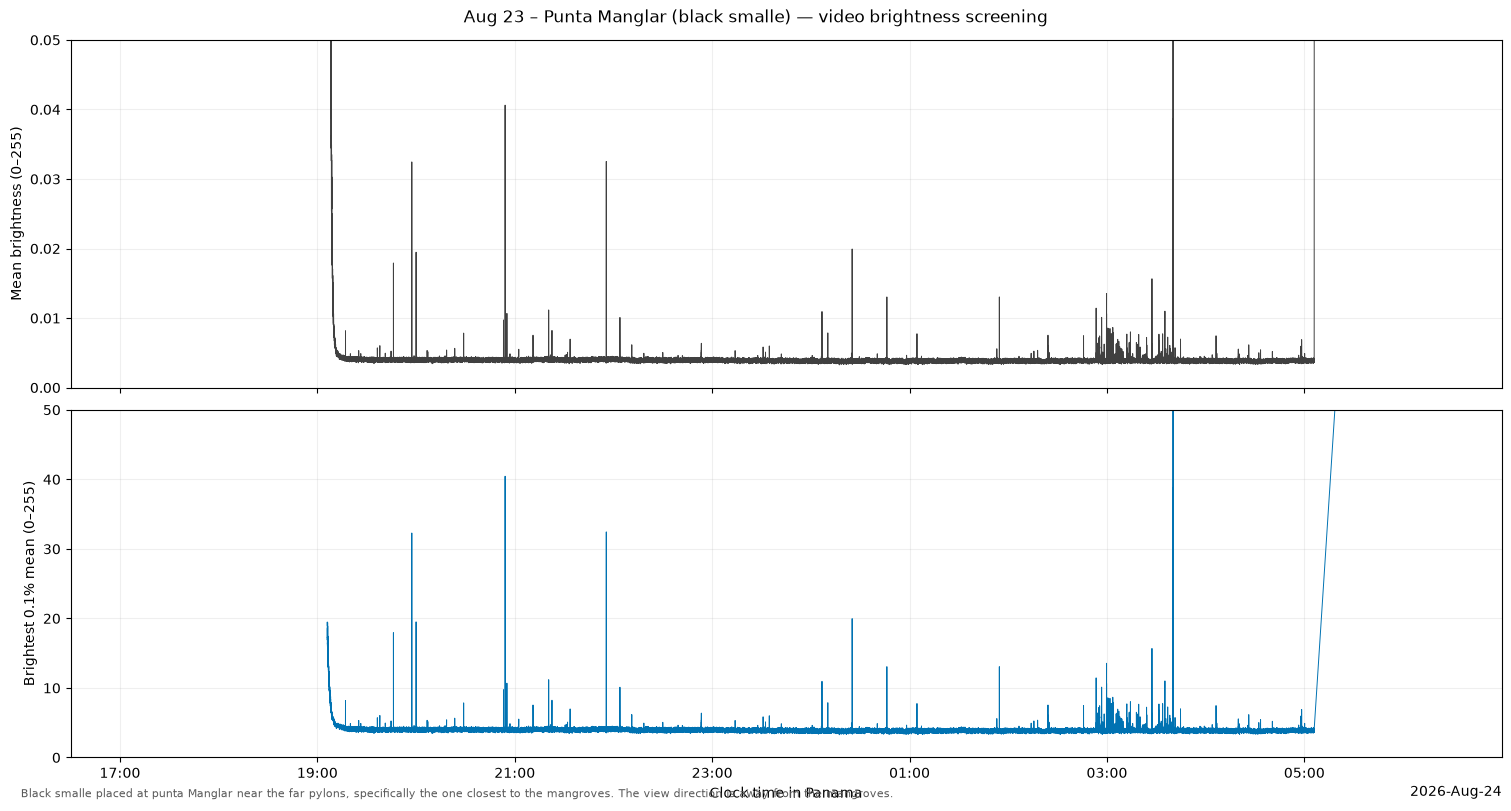

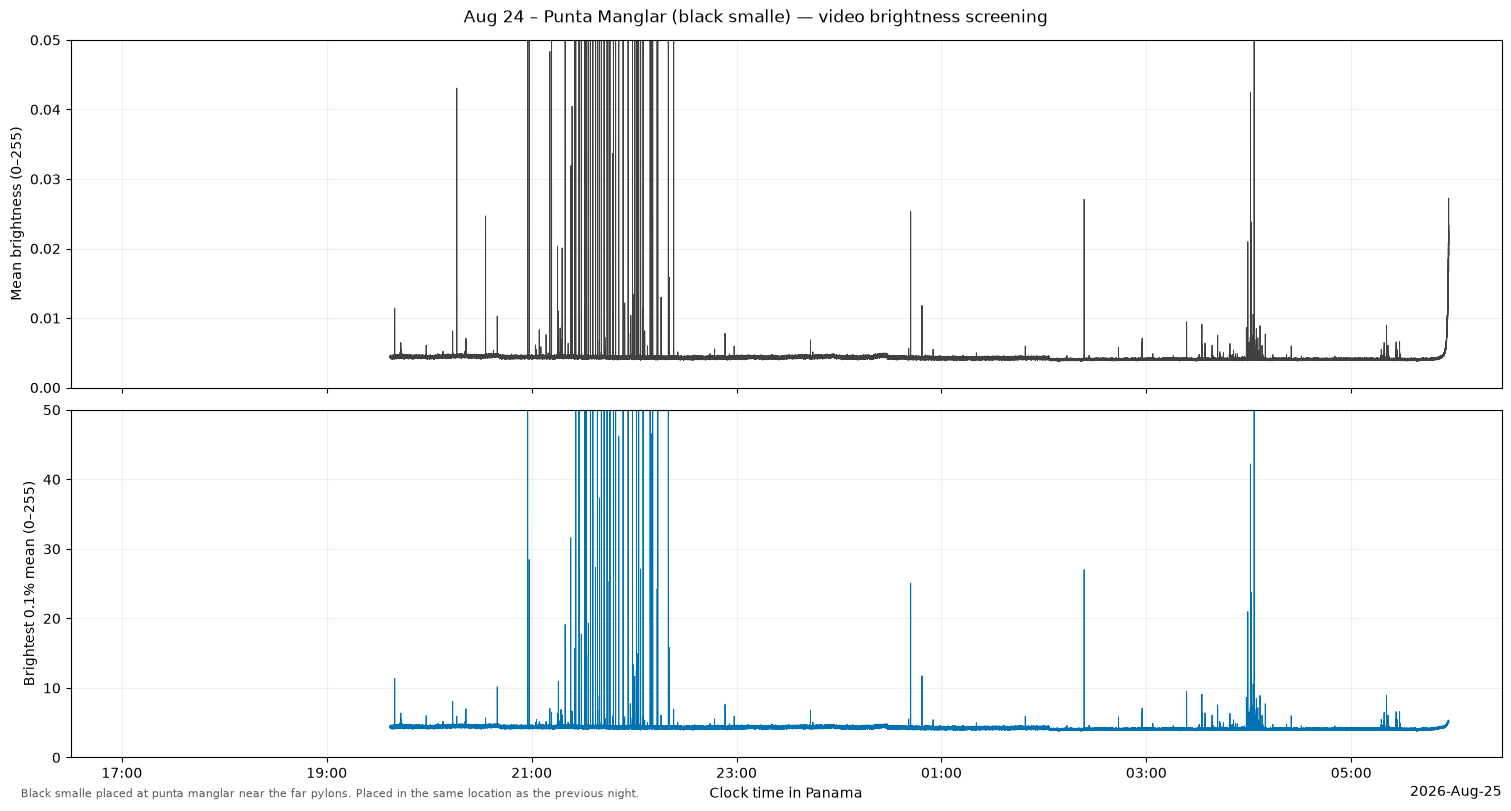

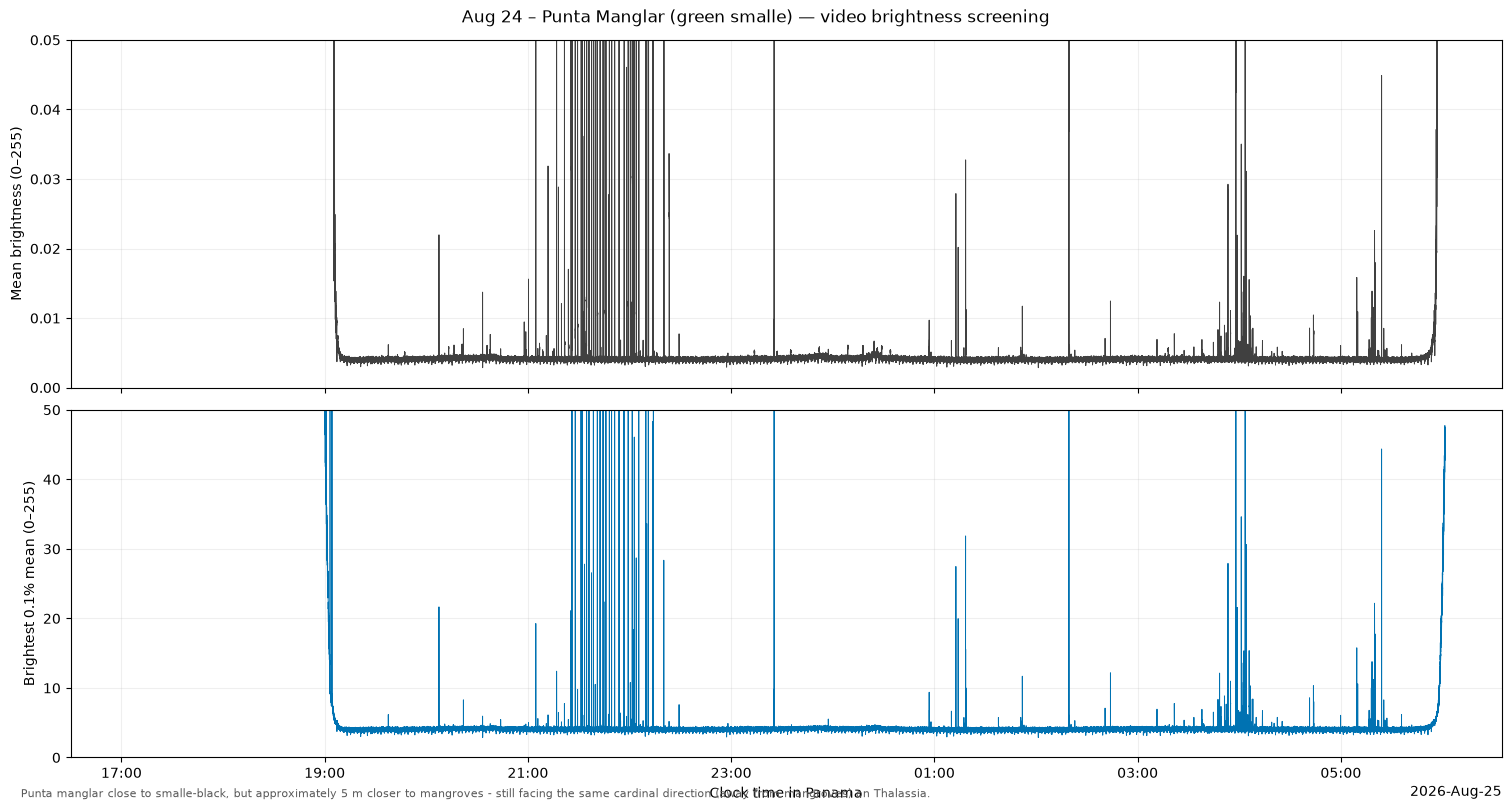

In [15]:
METRICS = ["mean_brightness", "top_fraction_mean", "brightness_percentile",
           "max_brightness", "fraction_above_threshold"]
GROUP_KEYS = ["video", "frame", "seconds_from_video_start", "time_utc"]

def load_and_average_views(run):
    view_frames = []
    for region in run["config"]["regions"]:
        for path in sorted(run["results_dir"].glob(f"*_{region}_brightness.csv")):
            frame = pd.read_csv(path); frame["camera_view"] = region; view_frames.append(frame)
    if not view_frames:
        return pd.DataFrame()
    camera_results = pd.concat(view_frames, ignore_index=True)
    expected = len(run["config"]["regions"])
    counts = camera_results.groupby(GROUP_KEYS)["camera_view"].nunique()
    complete_keys = counts[counts == expected].index
    incomplete_count = int((counts < expected).sum())
    if incomplete_count:
        print(f"Excluding {incomplete_count:,} rows missing a technical replicate.")
    complete = camera_results.set_index(GROUP_KEYS)
    complete = complete[complete.index.isin(complete_keys)].reset_index()
    averaged = complete.groupby(GROUP_KEYS, as_index=False)[METRICS].mean()
    averaged["technical_replicates"] = expected
    averaged["time_panama"] = pd.to_datetime(averaged["time_utc"], format="mixed", utc=True).dt.tz_convert(TIMEZONE)
    return averaged.sort_values("time_panama").reset_index(drop=True)

plot_results = {}
for dataset_key, run in dataset_runs.items():
    results = load_and_average_views(run)
    if results.empty:
        print(f"No completed results for {run['config']['label']}; skipping plot."); continue
    plot_results[dataset_key] = results
    fig, axes = plt.subplots(2, 1, figsize=(15, 8), sharex=True, constrained_layout=True)
    axes[0].plot(results["time_panama"], results["mean_brightness"], lw=0.7, color="0.25")
    axes[1].plot(results["time_panama"], results["top_fraction_mean"], lw=0.7, color="#0072B2")
    axes[0].set(ylabel="Mean brightness (0–255)", ylim=(0, MEAN_Y_AXIS_MAX))
    axes[1].set(ylabel="Brightest 0.1% mean (0–255)", xlabel="Clock time in Panama",
                ylim=(0, BRIGHT_Y_AXIS_MAX))
    # Anchor the observation night at 16:30, including when the first data arrive later.
    observation_date = (results["time_panama"].min() - pd.Timedelta(hours=12)).normalize()
    plot_start = observation_date + pd.Timedelta(hours=16, minutes=30)
    axes[1].set_xlim(left=plot_start)
    for axis in axes: axis.grid(alpha=0.2)
    locator = mdates.AutoDateLocator(minticks=4, maxticks=12)
    axes[1].xaxis.set_major_locator(locator)
    axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=ZoneInfo(TIMEZONE)))
    fig.suptitle(run["config"]["label"] + " — video brightness screening")
    fig.text(0.01, 0.01, run["config"]["notes"], fontsize=8, color="0.35")
    plt.show()

## Download and split videos around an observed signal

Choose a dataset and a Panama-time interval after inspecting the plots. The selection includes the last video beginning at or before the requested start, because that recording may overlap the start of the interval. Review `videos_to_extract` before running the following download cell.

Videos are downloaded one at a time and discarded after splitting. Only the camera views listed in the dataset's `regions` configuration are retained, so the white left camera from Aug 24 green is not saved.

In [9]:
# Example: Aug 24 green, around the feature visible from 21:30–21:40 Panama time.
SELECT_DATASET_KEY = "aug24_manglar_green"
SELECT_START_PANAMA = "2026-08-24 21:30:00"
SELECT_END_PANAMA = "2026-08-24 21:40:00"

if SELECT_DATASET_KEY not in dataset_runs:
    raise KeyError(f"Unknown dataset {SELECT_DATASET_KEY!r}; choose one of {list(dataset_runs)}")
selection_run = dataset_runs[SELECT_DATASET_KEY]
selection_config = selection_run["config"]
selection_videos = selection_run["videos"].copy()
selection_videos["start_panama"] = (
    pd.to_datetime(selection_videos["start_utc"], utc=True).dt.tz_convert(TIMEZONE)
)
range_start = pd.Timestamp(SELECT_START_PANAMA, tz=TIMEZONE)
range_end = pd.Timestamp(SELECT_END_PANAMA, tz=TIMEZONE)
if range_end < range_start:
    raise ValueError("SELECT_END_PANAMA must be at or after SELECT_START_PANAMA")

selected_indices = set(selection_videos.index[
    selection_videos["start_panama"].between(range_start, range_end, inclusive="both")
])
earlier = selection_videos.loc[selection_videos["start_panama"] <= range_start]
if not earlier.empty:
    selected_indices.add(earlier["start_panama"].idxmax())
videos_to_extract = (selection_videos.loc[sorted(selected_indices)]
                     .sort_values("start_panama").reset_index(drop=True))
if videos_to_extract.empty:
    raise RuntimeError("No videos found near the requested time range.")

print(f"Dataset: {selection_config['label']}")
print(f"Requested: {range_start} through {range_end}")
print(f"Keeping camera view(s): {selection_config['regions']}")
print(f"Selected {len(videos_to_extract)} videos (including the possible boundary video)")
display(videos_to_extract[["name", "size_GB", "start_panama"]]
        .style.format({"size_GB": "{:.3f}"}))

Dataset: Aug 24 – Punta Manglar (green smalle)
Requested: 2026-08-24 21:30:00-05:00 through 2026-08-24 21:40:00-05:00
Keeping camera view(s): ['right']
Selected 6 videos (including the possible boundary video)


,name,size_GB,start_panama
0,sbs_20260825_022917.mkv,0.001,2026-08-24 21:29:17-05:00
1,sbs_20260825_023117.mkv,0.004,2026-08-24 21:31:17-05:00
2,sbs_20260825_023317.mkv,0.002,2026-08-24 21:33:17-05:00
3,sbs_20260825_023517.mkv,0.002,2026-08-24 21:35:17-05:00
4,sbs_20260825_023717.mkv,0.003,2026-08-24 21:37:17-05:00
5,sbs_20260825_023917.mkv,0.003,2026-08-24 21:39:17-05:00


In [10]:
import cv2

SPLIT_VIDEO_DIR = PROJECT_ROOT / "data" / "selected_videos" / "split" / SELECT_DATASET_KEY
SPLIT_VIDEO_DIR.mkdir(parents=True, exist_ok=True)
views_to_keep = selection_config["regions"]

for video_number, item in enumerate(videos_to_extract.itertuples(index=False), start=1):
    output_paths = {
        view: SPLIT_VIDEO_DIR / f"{Path(item.name).stem}_{view}.mp4"
        for view in views_to_keep
    }
    pending_views = [view for view, path in output_paths.items() if not path.exists()]
    if not pending_views:
        print(f"Already split {video_number} of {len(videos_to_extract)}: {item.name}")
        continue

    print(f"\nDownloading {video_number} of {len(videos_to_extract)}: {item.name}")
    with tempfile.TemporaryDirectory(prefix=f"selected_{SELECT_DATASET_KEY}_") as temp_dir:
        local_video = Path(temp_dir) / item.name
        download_box_file(selection_run["shared_name"], item.id, local_video)
        capture = cv2.VideoCapture(str(local_video))
        if not capture.isOpened():
            raise RuntimeError(f"Could not open {item.name}")

        fps = capture.get(cv2.CAP_PROP_FPS)
        width = int(capture.get(cv2.CAP_PROP_FRAME_WIDTH))
        height = int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT))
        total_frames = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
        if width % 2:
            capture.release()
            raise RuntimeError(f"Side-by-side video width must be even; got {width}")
        half_width = width // 2
        codec = cv2.VideoWriter_fourcc(*"mp4v")
        writers = {
            view: cv2.VideoWriter(str(output_paths[view]), codec, fps, (half_width, height))
            for view in pending_views
        }
        if any(not writer.isOpened() for writer in writers.values()):
            capture.release()
            for writer in writers.values():
                writer.release()
            raise RuntimeError(f"Could not create split output for {item.name}")

        frame_number = 0
        try:
            while True:
                ok, frame = capture.read()
                if not ok:
                    break
                if "left" in writers:
                    writers["left"].write(frame[:, :half_width])
                if "right" in writers:
                    writers["right"].write(frame[:, half_width:])
                frame_number += 1
                if frame_number % 500 == 0 or frame_number == total_frames:
                    print(f"\rSplit {frame_number:,}/{total_frames:,} frames", end="")
        finally:
            capture.release()
            for writer in writers.values():
                writer.release()
        print()
    print(f"Saved {video_number} of {len(videos_to_extract)} to {SPLIT_VIDEO_DIR}")

print(f"\nFinished. Split videos are in {SPLIT_VIDEO_DIR}")


Downloaded 100.0%
Split 1,790/1,790 frames
Saved 1 of 6 to /Users/oakley/Documents/GitHub/manta-analysis/data/selected_videos/split/aug24_manglar_green

Downloaded 100.0%
Split 1,790/1,790 frames
Saved 2 of 6 to /Users/oakley/Documents/GitHub/manta-analysis/data/selected_videos/split/aug24_manglar_green

Downloaded 100.0%
Split 1,791/1,791 frames
Saved 3 of 6 to /Users/oakley/Documents/GitHub/manta-analysis/data/selected_videos/split/aug24_manglar_green

Downloaded 100.0%
Split 1,790/1,790 frames
Saved 4 of 6 to /Users/oakley/Documents/GitHub/manta-analysis/data/selected_videos/split/aug24_manglar_green

Downloaded 100.0%
Split 1,790/1,790 frames
Saved 5 of 6 to /Users/oakley/Documents/GitHub/manta-analysis/data/selected_videos/split/aug24_manglar_green

Downloaded 100.0%
Split 1,790/1,790 frames
Saved 6 of 6 to /Users/oakley/Documents/GitHub/manta-analysis/data/selected_videos/split/aug24_manglar_green

Finished. Split videos are in /Users/oakley/Documents/GitHub/manta-analysis/data/